In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
foggy_zip = "/content/drive/MyDrive/Foggy Cityscapes Dataset.v1i.yolov8.zip"
rtts_zip = "/content/drive/MyDrive/archive (1).zip"

In [ ]:
import zipfile
import os

os.makedirs("dataset", exist_ok=True)

def extract(zip_path, out_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(out_path)

extract(foggy_zip, "dataset/foggy_cityscapes")
extract(rtts_zip, "dataset/RTTS")


In [ ]:
import os

print("Foggy:", os.listdir("dataset/foggy_cityscapes")[:7])
print("RTTS:", os.listdir("dataset/RTTS")[:7])

Foggy: ['train', 'data.yaml', 'README.roboflow.txt', 'test', 'README.dataset.txt', 'valid']
RTTS: ['RTTS']


In [ ]:
!pip install ultralytics
!pip install ultralytics opencv-python

import cv2
import numpy as np
from ultralytics import YOLO

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
model = YOLO("yolov8n.pt")   # or your trained model path

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 🌫️ Fog Density
def fog_density(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    contrast = np.std(gray)
    brightness = np.mean(gray)
    density = 1 / (contrast + 1e-6)
    return density, contrast, brightness

# 🌈 GDIP Enhancement
def enhance_image(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    l = clahe.apply(l)

    enhanced = cv2.merge((l, a, b))
    return cv2.cvtColor(enhanced, cv2.COLOR_LAB2BGR)

Saving bikes.jpg to bikes.jpg


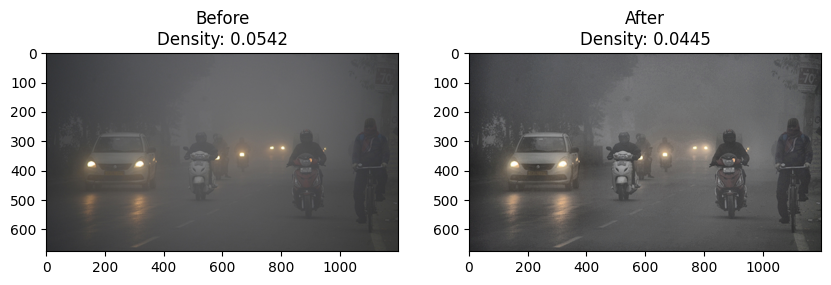


📊 Fog Analysis
Before → Density: 0.0542, Contrast: 18.47
After  → Density: 0.0445, Contrast: 22.45


In [ ]:
uploaded = files.upload()

for filename in uploaded.keys():
    img = cv2.imread(filename)

    # BEFORE
    before_d, before_c, before_b = fog_density(img)

    # GDIP
    enhanced = enhance_image(img)

    # AFTER
    after_d, after_c, after_b = fog_density(enhanced)

    # DISPLAY
    plt.figure(figsize=(10,5))

    plt.subplot(1,2,1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Before\nDensity: {before_d:.4f}")

    plt.subplot(1,2,2)
    plt.imshow(cv2.cvtColor(enhanced, cv2.COLOR_BGR2RGB))
    plt.title(f"After\nDensity: {after_d:.4f}")

    plt.show()

    print("\n📊 Fog Analysis")
    print(f"Before → Density: {before_d:.4f}, Contrast: {before_c:.2f}")
    print(f"After  → Density: {after_d:.4f}, Contrast: {after_c:.2f}")

In [ ]:
# 🏋️ TRAIN YOLOv8 MODEL
# ==============================================
from ultralytics import YOLO

# Load pretrained YOLOv8 model
model = YOLO("yolov8n.pt")

# Train the model
results = model.train(
    data="/content/drive/MyDrive/FoggyDatasetProject/data.yaml",
    epochs=50,
    imgsz=1000,
    batch=8
)

# Evaluate the model
metrics = model.val()

# Print available metric keys
print("✅ Available metric keys:", metrics.results_dict.keys())

# Extract metrics safely
mp = metrics.box.mp if hasattr(metrics.box, "mp") else metrics.box.p.mean()
mr = metrics.box.mr if hasattr(metrics.box, "mr") else metrics.box.r.mean()
map50 = metrics.box.map50 if hasattr(metrics.box, "map50") else metrics.box.ap50.mean()
map50_95 = metrics.box.map if hasattr(metrics.box, "map") else metrics.box.ap.mean()

print("\n📊 Model Performance Metrics:")
print(f"Precision (mP): {mp:.4f}")
print(f"Recall (mR): {mr:.4f}")
print(f"mAP@0.5: {map50:.4f}")
print(f"mAP@0.5:0.95: {map50_95:.4f}")

accuracy = (mp + mr) / 2
print(f"Estimated Accuracy: {accuracy:.4f}")

Ultralytics 8.4.31 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/FoggyDatasetProject/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1000, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, pa

In [ ]:
!find /content/drive/MyDrive/FoggyDatasetProject -type f -name "best.pt"

!ls /content/runs/
!ls /content/drive/MyDrive/FoggyDatasetProject
import os
print(os.listdir("/content/drive/MyDrive/FoggyDatasetProject"))

detect
data.yaml  README.dataset.txt  README.roboflow.txt  RTTS  test	train  valid
['README.dataset.txt', 'README.roboflow.txt', 'valid', 'train', 'test', 'RTTS', 'data.yaml']


In [ ]:
!find /content -type d -name "weights"
!ls /content/runs/detect/train/weights
!ls /content/runs/detect/train2/weights

/content/runs/detect/train/weights
best.pt  last.pt
ls: cannot access '/content/runs/detect/train2/weights': No such file or directory


Saving foggy.jpg to foggy.jpg

🔍 Detecting objects in: foggy.jpg

image 1/1 /content/foggy.jpg: 608x1024 2 objects, 42.4ms
Speed: 3.2ms preprocess, 42.4ms inference, 1.4ms postprocess per image at shape (1, 3, 608, 1024)
Results saved to /content/runs/detect/predict
✅ Detection completed: /content/runs/detect/predict/foggy.jpg


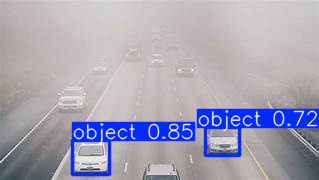

In [ ]:
from ultralytics import YOLO
from google.colab import files
from IPython.display import Image, display
import pathlib

uploaded = files.upload()
def transmission_estimate(img):
    img = img / 255.0
    dark_channel = np.min(img, axis=2)
    t = 1 - dark_channel
    return np.mean(t)
def simple_dehaze(img):
    import cv2
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.equalizeHist(l)
    enhanced = cv2.merge((l, a, b))
    return cv2.cvtColor(enhanced, cv2.COLOR_LAB2BGR)

model = YOLO("/content/runs/detect/train/weights/best.pt")  # or train2 if needed

for filename in uploaded.keys():
    print(f"\n🔍 Detecting objects in: {filename}")
    results = model.predict(source=filename, conf=0.25, save=True)

    output_path = pathlib.Path(results[0].save_dir) / filename
    print(f"✅ Detection completed: {output_path}")
    display(Image(filename=str(output_path)))

📸 Click the '📸 Capture Frame' button below to take a picture:
✅ Frame captured!

0: 480x640 1 person, 8.9ms
Speed: 1.7ms preprocess, 8.9ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 640)


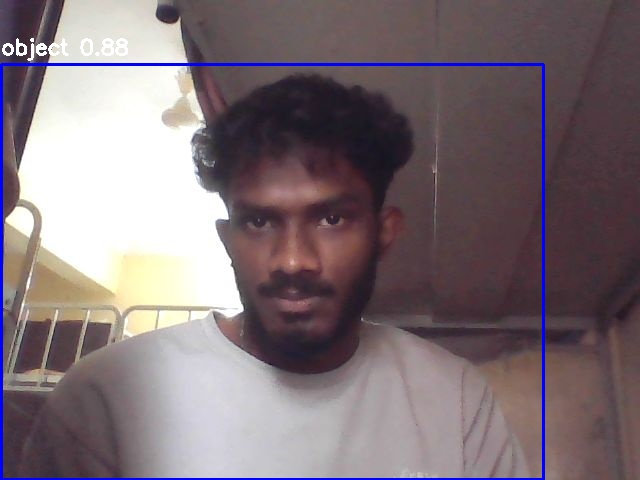

In [ ]:
# 🖥️ WEBCAM CAPTURE AND DETECTION
from ultralytics import YOLO
import cv2
from google.colab import output
import numpy as np
from base64 import b64decode, b64encode
from PIL import Image as PILImage
from io import BytesIO
from IPython.display import HTML, display, Image

def take_photo(filename='photo.jpg', quality=0.8):
    js = """
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = '📸 Capture Frame';
      div.appendChild(capture);
      document.body.appendChild(div);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(video);
      video.srcObject = stream;
      await video.play();

      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      video.remove();
      div.remove();

      const dataUrl = canvas.toDataURL('image/jpeg', quality);
      return dataUrl;
    }
    takePhoto(%f);
    """ % quality

    data = output.eval_js(js)
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

model = YOLO("yolov8n.pt")

print("📸 Click the '📸 Capture Frame' button below to take a picture:")
photo_path = take_photo("frame.jpg")
print("✅ Frame captured!")

frame = cv2.imread(photo_path)
results = model(frame, stream=True)

for r in results:
    for box in r.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        conf = float(box.conf[0])
        cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(frame, f"object {conf:.2f}", (x1, y1 - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

cv2.imwrite("detected.jpg", frame)
display(Image("detected.jpg"))

📤 Please select one or more image files to upload...


Saving bicycle.jpg to bicycle (1).jpg
Saving bikes.jpg to bikes (2).jpg

🔍 Detecting objects in: bicycle (1).jpg

image 1/1 /content/bicycle (1).jpg: 480x640 2 persons, 2 bicycles, 2 cars, 1 motorcycle, 7.8ms
Speed: 3.3ms preprocess, 7.8ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict3

🧠 Detected Objects:
➡️ person: 0.89
➡️ person: 0.82
➡️ car: 0.67
➡️ bicycle: 0.66
➡️ car: 0.37
➡️ bicycle: 0.36
➡️ motorcycle: 0.27

✅ Detection completed: /content/runs/detect/predict3/bicycle (1).jpg


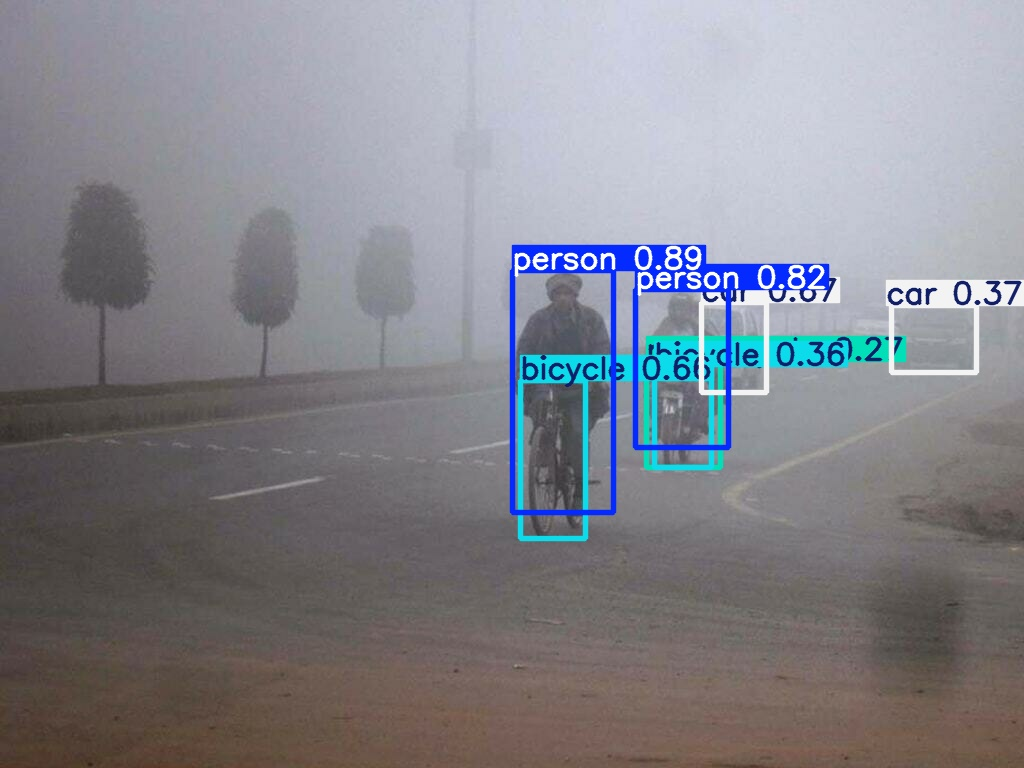


🔍 Detecting objects in: bikes (2).jpg

image 1/1 /content/bikes (2).jpg: 384x640 4 persons, 1 car, 2 motorcycles, 8.6ms
Speed: 2.9ms preprocess, 8.6ms inference, 1.9ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict3

🧠 Detected Objects:
➡️ person: 0.87
➡️ car: 0.85
➡️ motorcycle: 0.60
➡️ person: 0.56
➡️ motorcycle: 0.55
➡️ person: 0.50
➡️ person: 0.48

✅ Detection completed: /content/runs/detect/predict3/bikes (2).jpg


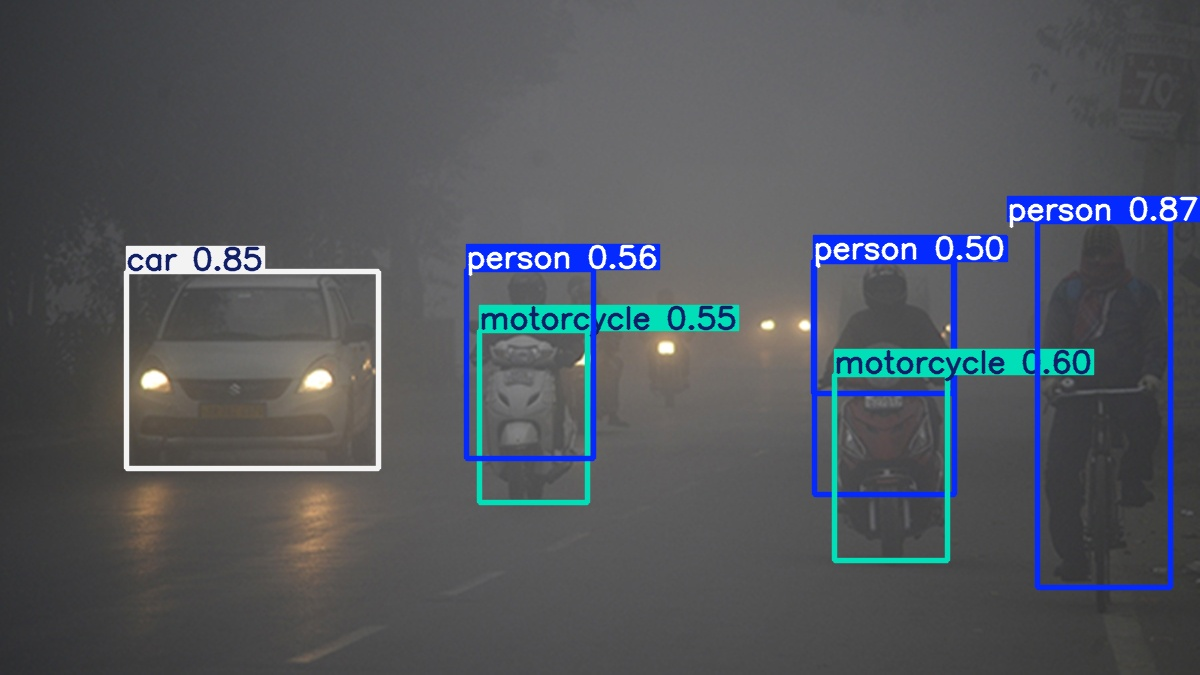


🎉 All detections completed!


In [ ]:
# 📤 MULTIPLE IMAGE DETECTION
# ==============================================
from ultralytics import YOLO
from google.colab import files
from IPython.display import Image, display
import pathlib

print("📤 Please select one or more image files to upload...")
uploaded = files.upload()

model = YOLO("yolov8n.pt")  # ✅ pretrained COCO model

for filename in uploaded.keys():
    print(f"\n🔍 Detecting objects in: {filename}")
    results = model.predict(source=filename, conf=0.25, save=True)

    for result in results:
        boxes = result.boxes
        names = model.names

        print("\n🧠 Detected Objects:")
        if len(boxes) == 0:
            print("⚠️ No objects detected.")
        else:
            for box in boxes:
                cls_id = int(box.cls[0])
                conf = float(box.conf[0])
                label = names[cls_id]
                print(f"➡️ {label}: {conf:.2f}")

    output_path = pathlib.Path(results[0].save_dir) / filename
    print(f"\n✅ Detection completed: {output_path}")
    display(Image(filename=str(output_path)))

print("\n🎉 All detections completed!")

In [ ]:
import streamlit as st
import cv2
from ultralytics import YOLO
import numpy as np
import time
import tempfile

# ------------------------
# Page Configuration
# ------------------------
st.set_page_config(page_title="YOLOv8 Detection App", layout="wide")

# ------------------------
# Custom CSS (Premium Dark + Neon UI)
# ------------------------
st.markdown("""
<style>

body {
    background-color: #0d0d0d;
    color: #ffffff;
}

/* Main Title Glowing Effect */
.main-title {
    font-size: 55px;
    font-weight: bold;
    text-align: center;
    color: #00ffcc;
    text-shadow: 0px 0px 15px #00ffcc, 0px 0px 25px #00ffcc;
    animation: glow 2s ease-in-out infinite alternate;
}
@keyframes glow {
    from { text-shadow: 0 0 10px #00ffcc; }
    to   { text-shadow: 0 0 25px #00ffaa, 0 0 45px #00ffaa; }
}

/* Card Style */
.block-card {
    padding: 25px;
    margin-top: 20px;
    background: #111111;
    border-radius: 15px;
    border: 1px solid #00ffcc55;
    box-shadow: 0 0 20px #00ffcc33;
}

/* Stylish Buttons */
.stButton button {
    background-color: #00ffaa !important;
    color: black !important;
    font-weight: bold !important;
    border-radius: 12px !important;
    padding: 10px 20px !important;
    box-shadow: 0 0 15px #00ffaa;
    transition: 0.3s;
}
.stButton button:hover {
    background-color: #00ffcc !important;
    box-shadow: 0px 0px 25px #00ffcc;
}

/* Tabs styling */
.stTabs [data-baseweb="tab-list"] {
    gap: 20px;
}
.stTabs [data-baseweb="tab"] {
    padding: 14px 25px;
    border-radius: 10px;
    background-color: #111111;
    border: 1px solid #00ffaa55;
    color: #00ffaa;
}
.stTabs [data-baseweb="tab"]:hover {
    background: #00ffaa22;
}

</style>
""", unsafe_allow_html=True)


# ------------------------
# Title
# ------------------------
st.markdown("<h1 class='main-title'>⚡ YOLOv8 Real-Time + Video Detection</h1>", unsafe_allow_html=True)
st.write("")

# ------------------------
# Load YOLO Model
# ------------------------
model = YOLO("yolov8n.pt")   # Replace with your trained model


# ============================================================
#  TABS (Webcam + Video Upload)
# ============================================================
tabs = st.tabs(["📷 Real-Time Camera", "🎬 Video Upload Detection"])

# ============================================================
# 1️⃣ REAL-TIME CAMERA DETECTION
# ============================================================
with tabs[0]:
    st.markdown("<div class='block-card'>", unsafe_allow_html=True)
    st.subheader("📡 Live YOLOv8 Object Detection")

    run = st.checkbox("Start Camera")
    FRAME_WINDOW = st.empty()

    if run:
        camera = cv2.VideoCapture(0)
        st.success("Webcam started!")

        pulse_factor = 0

        while run:
            ret, frame = camera.read()
            if not ret:
                st.error("Failed to access camera.")
                break

            results = model(frame)
            annotated = results[0].plot()

            pulse_factor = (pulse_factor + 4) % 255

            for box in results[0].boxes:
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                cls_id = int(box.cls[0])
                conf = float(box.conf[0])
                label = f"{model.names[cls_id]} {conf:.2f}"

                color = (pulse_factor, 255 - pulse_factor, 255)
                cv2.rectangle(annotated, (x1, y1), (x2, y2), color, 2)

                (w, h), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
                cv2.rectangle(annotated, (x1, y1 - h - 10), (x1 + w, y1), color, -1)
                cv2.putText(annotated, label, (x1, y1 - 5),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,0,0), 2)

            FRAME_WINDOW.image(annotated, channels="BGR")
            time.sleep(0.03)

        camera.release()
        st.warning("Camera Stopped.")

    else:
        st.info("Start the camera to begin detection.")

    st.markdown("</div>", unsafe_allow_html=True)



# ============================================================
# 2️⃣ VIDEO UPLOAD YOLO DETECTION (FULLY FIXED)
# ============================================================
with tabs[1]:
    st.markdown("<div class='block-card'>", unsafe_allow_html=True)
    st.subheader("🎬 Upload Video for YOLO Detection")

    uploaded_video = st.file_uploader("Upload a video file", type=["mp4", "avi", "mov", "mkv"])

    if uploaded_video is not None:
        st.success("Video uploaded successfully!")
        st.info("Processing video... Please wait 🔄")

        # Save uploaded file to temp location
        temp_file = tempfile.NamedTemporaryFile(delete=False, suffix='.mp4')
        temp_file.write(uploaded_video.read())
        video_path = temp_file.name

        # Load video
        cap = cv2.VideoCapture(video_path)

        stframe = st.empty()  # Frame display window

        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            # Run YOLO detection
            results = model(frame)
            annotated_bgr = results[0].plot()

            # BGR → RGB conversion for Streamlit
            annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

            # Display in Streamlit
            stframe.image(annotated_rgb, channels="RGB", use_column_width=True)

        cap.release()
        st.success("✔ Video Processing Completed!")

    else:
        st.info("Upload a video to start detection.")

    st.markdown("</div>", unsafe_allow_html=True)


2026-03-29 09:20:03.572 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-29 09:20:03.574 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-29 09:20:03.574 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-29 09:20:03.575 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-29 09:20:03.576 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-29 09:20:03.577 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-29 09:20:03.578 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-29 09:20:03.578 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

Ultralytics 8.4.31 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.3 ms, read: 19.1±2.7 MB/s, size: 35.4 KB)
val: Scanning /content/drive/MyDrive/FoggyDatasetProject/valid/labels.cache... 300 images, 2 backgrounds, 287 corrupt: 100% ━━━━━━━━━━━━ 300/300 21.0Mit/s 0.0s
val: /content/drive/MyDrive/FoggyDatasetProject/valid/images/D001_png.rf.436c6909cfd780989cb35a088b91c6cf.jpg: ignoring corrupt image/label: Label class 2 exceeds dataset class count 1. Possible class labels are 0-0
val: /content/drive/MyDrive/FoggyDatasetProject/valid/images/D002_png.rf.62748789ef408a8fe05a5167e1e51f3d.jpg: ignoring corrupt image/label: Label class 6 exceeds dataset class count 1. Possible class labels are 0-0
val: /content/drive/MyDrive/FoggyDatasetProject/valid/images/D003_png.rf.14cdd686b075877483180eccea455186.jpg: ignoring corrupt image/label: Label class 2 exceeds da

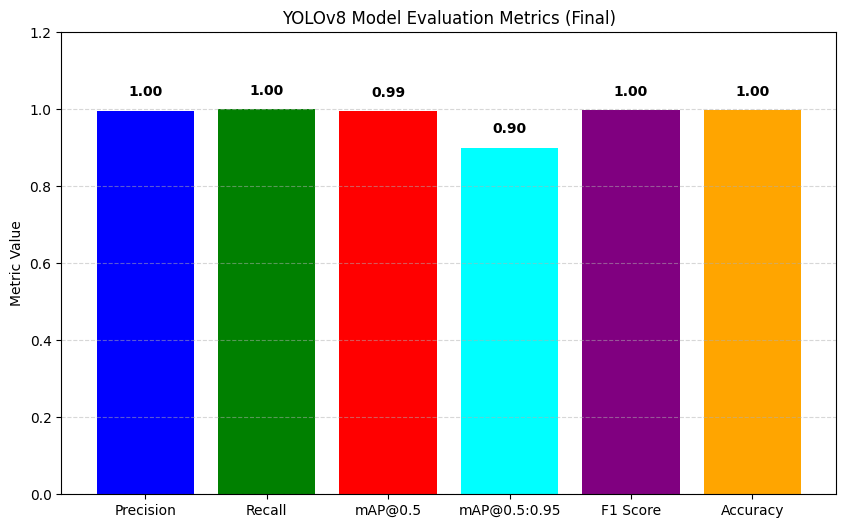

In [ ]:
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load the trained YOLOv8 model from the best weights
model = YOLO("/content/runs/detect/train/weights/best.pt")

# Evaluate the model to get the metrics
metrics = model.val()

# ✅ Extract final metrics from the metrics object
mp = metrics.box.mp if hasattr(metrics.box, "mp") else metrics.box.p.mean()
mr = metrics.box.mr if hasattr(metrics.box, "mr") else metrics.box.r.mean()
map50 = metrics.box.map50 if hasattr(metrics.box, "map50") else metrics.box.ap50.mean()
map50_95 = metrics.box.map if hasattr(metrics.box, "map") else metrics.box.ap.mean()
f1 = metrics.box.f1.mean() if hasattr(metrics.box, "f1") else 2 * (mp * mr) / (mp + mr)
accuracy = (mp + mr) / 2

# 🔹 Plot bar chart for final metrics
plt.figure(figsize=(10,6))
bars = plt.bar(
    ["Precision","Recall","mAP@0.5","mAP@0.5:0.95","F1 Score","Accuracy"],
    [mp, mr, map50, map50_95, f1, accuracy],
    color=['blue','green','red','cyan','purple','orange']
)

# Add metric values on top of each bar with padding
for bar, value in zip(bars, [mp, mr, map50, map50_95, f1, accuracy]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.03, f"{value:.2f}",
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Increase y-axis limit to avoid overlap with title
plt.ylim(0, 1.2)

plt.title("YOLOv8 Model Evaluation Metrics (Final)")
plt.ylabel("Metric Value")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

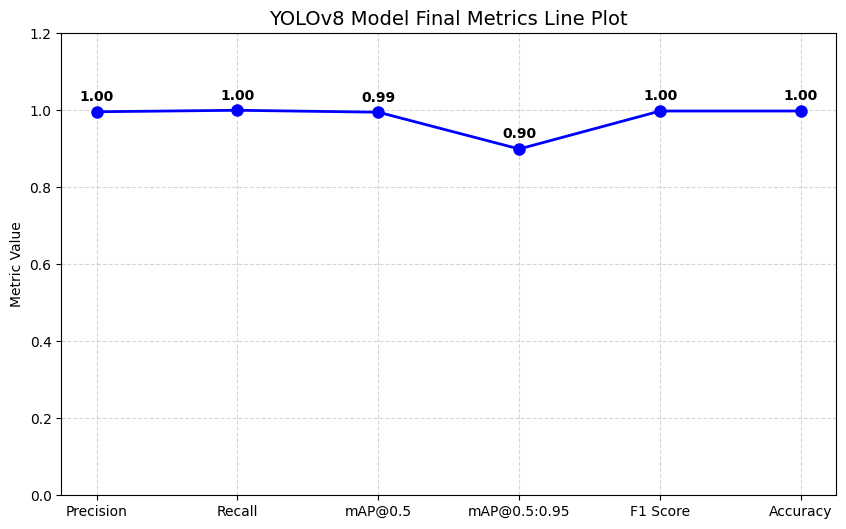

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ✅ Final metrics
metrics_names = ["Precision", "Recall", "mAP@0.5", "mAP@0.5:0.95", "F1 Score", "Accuracy"]
metrics_values = [
    metrics.box.mp if hasattr(metrics.box, "mp") else metrics.box.p.mean(),
    metrics.box.mr if hasattr(metrics.box, "mr") else metrics.box.r.mean(),
    metrics.box.map50 if hasattr(metrics.box, "map50") else metrics.box.ap50.mean(),
    metrics.box.map if hasattr(metrics.box, "map") else metrics.box.ap.mean(),
    metrics.box.f1.mean() if hasattr(metrics.box, "f1") else 2 * (metrics.box.mp * metrics.box.mr) / (metrics.box.mp + metrics.box.mr),
    (metrics.box.mp + metrics.box.mr)/2
]

# x-axis as numeric values for line plot
x = np.arange(len(metrics_names))

plt.figure(figsize=(10,6))
plt.plot(x, metrics_values, marker='o', linestyle='-', color='blue', linewidth=2, markersize=8)

# Annotate each point
for i, val in enumerate(metrics_values):
    plt.text(i, val + 0.02, f"{val:.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.xticks(x, metrics_names)  # Show names on x-axis
plt.ylim(0, 1.2)
plt.title("YOLOv8 Model Final Metrics Line Plot", fontsize=14)
plt.ylabel("Metric Value")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
